In [1]:
# ==============================================================================
# 0. インポートと初期設定
# ==============================================================================

In [1]:
import warnings
import time
import numpy as np
import scipy as sp
from sympy import symbols
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.linalg import sqrtm, expm
import pickle
import os
from typing import List, Dict, Optional, Tuple
import concurrent.futures

# pytket関連のインポート
from pytket import Circuit, Qubit
from pytket.pauli import Pauli, QubitPauliString
from pytket.utils.operators import QubitPauliOperator
from pytket.utils.expectations import expectation_from_counts, expectation_from_shots, get_operator_expectation_value
from pytket.circuit import OpType, PauliExpBox
from pytket.circuit.display import render_circuit_jupyter as draw
from pytket.extensions.qiskit import AerBackend
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.backends import ResultHandle
from pytket.backends.status import StatusEnum

import qermit
from qermit.zero_noise_extrapolation.zne import Folding, gen_ZNE_MitEx
from qermit.spam.spam_mitres import gen_FullyCorrelated_SPAM_MitRes
from pytket.utils.outcomearray import OutcomeArray
from qermit.taskgraph.mitex import ObservableExperiment, AnsatzCircuit, ObservableTracker
from pytket.passes import DecomposeBoxes, FullPeepholeOptimise
from pytket.predicates import CompilationUnit

# Qermitのインポート
import qermit
from qermit.spam.spam_mitres import gen_FullyCorrelated_SPAM_MitRes
from qermit.zero_noise_extrapolation.zne import Folding, Fit

# --- Qermitの低レベルな部品をインポート ---
from qermit.spam.full_spam_correction import (
    gen_full_tomography_spam_circuits_task,
    gen_full_tomography_spam_characterisation_task,
    gen_full_tomography_spam_correction_task,
)

# Qiskitのインポート
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import HamiltonianGate
from qiskit.quantum_info import SparsePauliOp, Operator

# MatplotlibとSeabornのスタイル設定
warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams["figure.dpi"] = 300
sns.set(color_codes=True, context='paper', style="whitegrid")

# Hamiltonian

In [2]:
# ==============================================================================
# 1. ハミルトニアン定義
# ==============================================================================

In [3]:
def xxz_ham_qiskit(n_sites, delta):
    """XXZ模型のハミルトニアンを物理系（Object）用に生成"""
    paulis, coeffs = [], []
    h = (1 - delta) / 2
    for i in range(n_sites - 1):
        for pauli, weight in zip(['XX', 'YY', 'ZZ'], [-0.25, -0.25, -0.25 * delta]):
            pauli_str = ['I'] * n_sites
            pauli_str[i], pauli_str[i+1] = pauli[0], pauli[1]
            paulis.append("".join(pauli_str))
            coeffs.append(weight)
    for i in range(n_sites):
        pauli_str = ['I'] * n_sites
        pauli_str[i] = 'Z'
        paulis.append("".join(pauli_str))
        coeffs.append(-h)
    return SparsePauliOp(paulis, coeffs)

In [4]:
def xxz_ham_pytket(n_sites: int, delta: float) -> QubitPauliOperator:
    """XXZ模型のハミルトニアンをpytketのQubitPauliOperatorとして生成"""
    op_dict: Dict[QubitPauliString, float] = {}
    h = (1 - delta) / 2
    for i in range(n_sites - 1):
        for pauli_enum, weight in zip([(Pauli.X, Pauli.X), (Pauli.Y, Pauli.Y), (Pauli.Z, Pauli.Z)], [-0.25, -0.25, -0.25 * delta]):
            qps = QubitPauliString([Qubit("Object", i), Qubit("Object", i+1)], [pauli_enum[0], pauli_enum[1]])
            op_dict[qps] = weight
    for i in range(n_sites):
        qps = QubitPauliString(Qubit("Object", i), Pauli.Z)
        op_dict[qps] = -h
    return QubitPauliOperator(op_dict)

In [5]:
def shift_hamiltonian_indices(
    hamiltonian: QubitPauliOperator,
    shift: int
) -> QubitPauliOperator:
    """
    ハミルトニアン内の全量子ビットのインデックスを指定した数だけシフトさせる。
    """
    shifted_op_dict = {}
    for pauli_string, coeff in hamiltonian._dict.items():
        new_string_map = {}
        for qubit, pauli in pauli_string.map.items():
            shifted_qubit = Qubit(qubit.reg_name, qubit.index[0] + shift)
            new_string_map[shifted_qubit] = pauli
        shifted_pauli_string = QubitPauliString(new_string_map)
        shifted_op_dict[shifted_pauli_string] = coeff
    return QubitPauliOperator(shifted_op_dict)

# Variational quantum circuits for preparing Gibbs state

In [6]:
# ==============================================================================
# 2. VQA回路 (Ansatz) の構築
# ==============================================================================

In [7]:
def rp_pytket(circuit: Circuit, a: Qubit, b: Qubit, alpha, beta):
    """カスタムRPゲートシーケンス (pytket版)"""
    PI = 1.0
    PI_HALF = 0.5
    circuit.Rz(-PI, a); circuit.Rx(PI_HALF, a); circuit.Rz(-PI_HALF, a)
    circuit.Rz(-PI_HALF, b); circuit.Rx(PI_HALF, b); circuit.Rz(-PI, b)
    circuit.CX(a, b)
    circuit.Rx(PI_HALF, a); circuit.Rz(-alpha / np.pi, a); circuit.Rx(PI_HALF, a)
    circuit.Rz(beta / np.pi, b)
    circuit.CX(a, b)
    circuit.Rz(-PI_HALF, a); circuit.Rx(PI_HALF, a); circuit.Rz(-PI, a)
    circuit.Rz(-PI, b); circuit.Rx(PI_HALF, b); circuit.Rz(-PI_HALF, b)
    return circuit

In [8]:
def apply_cnot_layer_pytket(circuit: Circuit, q_reg, reverse: bool = False):
    """構造化されたCNOT層 (pytket版)"""
    pairs = [(0, 1), (2, 3), (1, 2), (0, 3)]
    if reverse:
        pairs = list(reversed(pairs))
    for a, b in pairs:
        circuit.CX(q_reg[a], q_reg[b])
    return circuit

In [9]:
def get_vqa_circuits_pytket(n_sites: int):
    """VQA用のシンボリック回路を生成する (pytket版)"""
    num_params = n_sites + n_sites * (n_sites - 1) + 8 * (n_sites - 1)
    params = symbols(f'P_:{num_params}')
    param_idx = 0
    circuit = Circuit()
    q_ancilla = circuit.add_q_register("Ancilla", n_sites)
    q_object = circuit.add_q_register("Object", n_sites)

    for i in range(n_sites):
        circuit.Ry(params[param_idx] / np.pi, q_ancilla[i])
        param_idx += 1
    circuit.add_barrier(q_ancilla)
    
    for i in range(n_sites - 1):
        apply_cnot_layer_pytket(circuit, q_ancilla, reverse=(i % 2 == 1))
        for j in range(n_sites):
            circuit.Ry(params[param_idx] / np.pi, q_ancilla[j])
            param_idx += 1
        circuit.add_barrier(q_ancilla)
    
    for i in range(n_sites):
        circuit.CX(q_ancilla[i], q_object[i])
    rp_pairs = [(q_object[0], q_object[1]), (q_object[2], q_object[3]),
                (q_object[1], q_object[2]), (q_object[0], q_object[3])]
    for i in range(n_sites - 1):
        for a_q, b_q in rp_pairs:
            rp_pytket(circuit, a_q, b_q, params[param_idx], params[param_idx+1])
            param_idx += 2
        if i < n_sites - 2:
            circuit.add_barrier(q_object)
            
    circuit_est = circuit.copy()
    circuit_samp = circuit.copy()
    creg = circuit_samp.add_c_register("Creg", n_sites)
    circuit_samp.add_barrier(q_ancilla)
    for i in range(n_sites):
        circuit_samp.Measure(q_ancilla[i], creg[i])
        
    return circuit_est, circuit_samp, params

In [10]:
# ==============================================================================
# 3. VQAによるギブス状態準備 (最適化)
# ==============================================================================

In [11]:
def cost_func_gibbs_pytket(param_values, sym_params, circ_est, circ_samp, backend, hamiltonian, beta):
    """ギブス状態準備のためのコスト関数（変分自由エネルギー）"""
    param_map = dict(zip(sym_params, param_values))
    circ_est_bound = circ_est.copy()
    circ_est_bound.symbol_substitution(param_map)
    ev_ave = get_operator_expectation_value(circ_est_bound, hamiltonian, backend, n_shots=4096)
    circ_samp_bound = circ_samp.copy()
    circ_samp_bound.symbol_substitution(param_map)
    counts = backend.run_circuit(circ_samp_bound, n_shots=4096).get_counts()
    total_counts = sum(counts.values())
    entropy_ave = -sum(
        (freq / total_counts) * np.log2(freq / total_counts) if freq > 0 else 0
        for freq in counts.values()
    )
    cost = ev_ave.real - entropy_ave / beta
    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = param_values
    cost_history_dict["cost_history"].append(cost)
    return cost

In [12]:
def run_vqa_optimization_pytket(n_sites, delta, beta, maxiter=400):
    """pytketを用いてローカルシミュレータでVQA最適化を実行"""
    print(f"--- Starting VQA for Gibbs State (Δ={delta}, β={beta}) ---")
    hamiltonian = xxz_ham_pytket(n_sites, delta)
    circ_est, circ_samp, sym_params = get_vqa_circuits_pytket(n_sites)
    backend = AerBackend()
    initial_params = 2 * np.pi * np.random.rand(len(sym_params))
    print(f"Running scipy.optimize.minimize with COBYLA (maxiter={maxiter})...")
    res = minimize(
        cost_func_gibbs_pytket, initial_params,
        args=(sym_params, circ_est, circ_samp, backend, hamiltonian, beta),
        method="COBYLA", options={'maxiter': maxiter}
    )
    all(cost_history_dict["prev_vector"] == res.x)
    print("\nOptimization finished.")
    print(f"Final cost for Δ={delta}: {res.fun}")
    
    # === 変更点: プロットのファイル名にdelta値を含める ===
    # fig, ax = plt.subplots()
    # ax.plot(range(cost_history_dict["iters"]), cost_history_dict["cost_history"])
    # ax.set_xlabel("Iterations"); ax.set_ylabel("Cost (Variational Free Energy)")
    # ax.set_title(f"VQA Optimization History (Δ={delta})")
    # ファイル名にdelta値を追加
    # fig.savefig(f'VQA_Cost_History_pytket_delta_{delta:.1f}.pdf', dpi=300, bbox_inches="tight")
    # plt.show() # バッチ実行中は表示しない方がスムーズ
    # plt.close(fig) # メモリを解放

    return res.x.tolist()

In [13]:
# ==============================================================================
# 4. Fidelity検証
# ==============================================================================

In [14]:
# --- Fidelity検証 & 数値計算用関数 ---
def partial_trace(rho, dimA, dimB):
    rho_B = np.zeros((dimB, dimB), dtype=complex)
    for i in range(dimA):
        rho_B += rho[i*dimB:(i+1)*dimB, i*dimB:(i+1)*dimB]
    return rho_B

def state_fidelity(A, B):
    sqrt_A = sqrtm(A)
    return np.real(np.trace(sqrtm(sqrt_A @ B @ sqrt_A)))

def gibbs_state(beta, A):
    exp_A = expm(-beta * A)
    return exp_A / np.trace(exp_A)

def get_optimized_circuit_pytket(n_sites: int, optimized_params: list) -> Circuit:
    circ_est_sym, _, sym_params = get_vqa_circuits_pytket(n_sites)
    param_map = dict(zip(sym_params, optimized_params))
    bound_circuit = circ_est_sym.copy()
    bound_circuit.symbol_substitution(param_map)
    return bound_circuit

def verify_fidelity_pytket(n_sites: int, delta: float, beta: float, optimized_params: list):
    print(f"\n--- Verifying Fidelity for Δ={delta} ---")
    vqa_circuit = get_optimized_circuit_pytket(n_sites, optimized_params)
    u_mat = vqa_circuit.get_unitary()
    ham_op = xxz_ham_pytket(n_sites, delta)
    object_qubits = [Qubit("Object", i) for i in range(n_sites)]
    ham_mat = ham_op.to_sparse_matrix(object_qubits).toarray()
    exact_gibbs = gibbs_state(beta, ham_mat)
    ket_0 = np.zeros(2**(2*n_sites)); ket_0[0] = 1
    rho_full = u_mat @ np.outer(ket_0, ket_0) @ u_mat.T.conj()
    rho_reduced = partial_trace(rho_full, 2**n_sites, 2**n_sites)
    f = state_fidelity(exact_gibbs, rho_reduced)
    print(f"Fidelity for Δ={delta}: {f:.6f}")
    return f

# Measuring OTOC

In [15]:
# ==============================================================================
# 5. OTOC計算
# ==============================================================================

In [16]:
def commutator(A, B):
    return A @ B - B @ A

def calc_otoc(A, B, C):
    Com_AB = commutator(A, B)
    return -np.real(np.trace(Com_AB @ Com_AB @ C))

def otoc_num(rho, H, W, V, t):
    W_t = expm(1j * t * H) @ W @ expm(-1j * t * H)
    return calc_otoc(W_t, V, rho)

def calculate_numerical_otoc_pytket(n_sites: int, hamiltonian: QubitPauliOperator, vqa_base_circuit: Circuit, t_list: np.ndarray):
    print("--- Calculating Numerical OTOC (from VQA State) ---")
    u_mat = vqa_base_circuit.get_unitary()
    ket_0 = np.zeros(2**(2*n_sites)); ket_0[0] = 1
    rho_full = u_mat @ np.outer(ket_0, ket_0) @ u_mat.T.conj()
    rho_object = partial_trace(rho_full, 2**n_sites, 2**n_sites)
    w_op = QubitPauliOperator({QubitPauliString(Qubit("Object", 0), Pauli.X): 1.0})
    object_qubits = [Qubit("Object", i) for i in range(n_sites)]
    mat_h = hamiltonian.to_sparse_matrix(object_qubits).toarray()
    mat_w = w_op.to_sparse_matrix(object_qubits).toarray()
    otoc_list = [otoc_num(rho_object, mat_h, mat_w, mat_w, t) for t in t_list]
    print("Numerical calculation finished.")
    return otoc_list

In [17]:
def add_time_evolution(circuit: Circuit, hamiltonian: QubitPauliOperator, time: float):
    for pauli_string, coeff in hamiltonian._dict.items():
        if pauli_string:
            qubits, paulis = zip(*pauli_string.map.items())
            phase = np.real((2*time*coeff)/np.pi)
            pbox = PauliExpBox(list(paulis), phase)
            circuit.add_gate(pbox, list(qubits))
    return circuit

In [18]:
# ==============================================================================
# OTOC回路の構築
# ==============================================================================

In [19]:
def create_otoc_circuit_pytket(vqa_base_circuit: Circuit, hamiltonian: QubitPauliOperator, t: float) -> Circuit:
    circuit = vqa_base_circuit.copy()
    q_control = circuit.add_q_register("Control", 1)[0]
    q_object = [q for q in vqa_base_circuit.qubits if q.reg_name == "Object"]
    circuit.H(q_control)
    circuit.CX(q_control, q_object[0])
    add_time_evolution(circuit, hamiltonian, t)
    circuit.X(q_object[0])
    add_time_evolution(circuit, hamiltonian, -t)
    circuit.X(q_control)
    circuit.CX(q_control, q_object[0])
    circuit.X(q_control)
    return circuit

In [20]:
def calculate_simulation_otoc_pytket(n_sites: int, hamiltonian: QubitPauliOperator, vqa_base_circuit: Circuit, t_list: np.ndarray, iteration: int, shots: int):
    print("--- Running simulation using rewinding time method ---")
    backend = AerBackend()
    control_x_op = QubitPauliOperator({QubitPauliString(Qubit("Control", 0), Pauli.X): 1.0})
    control_y_op = QubitPauliOperator({QubitPauliString(Qubit("Control", 0), Pauli.Y): 1.0})
    otoc_means, otoc_stds = [], []
    print("Running simulations for all time points...")
    for t in t_list:
        otoc_circuit_t = create_otoc_circuit_pytket(vqa_base_circuit, hamiltonian, t)        
        evs_for_t_x = []
        evs_for_t_y = []
        for _ in range(iteration):
            exp_val_x = get_operator_expectation_value(otoc_circuit_t, control_x_op, backend, n_shots=shots)
            evs_for_t_x.append(np.real(exp_val_x))
            exp_val_y = get_operator_expectation_value(otoc_circuit_t, control_y_op, backend, n_shots=shots)
            evs_for_t_y.append(np.real(exp_val_y))
        otocs_prod_for_t = np.array(evs_for_t_x) + 1j * np.array(evs_for_t_y)
        otocs_com_for_t = 2 * (1 - np.real(otocs_prod_for_t))
        otoc_means.append(np.mean(otocs_com_for_t))
        otoc_stds.append(np.std(otocs_com_for_t))
        print(f"t = {t:.2f} done.", end="\r")
    print("\nSimulation finished.")
    return otoc_means, otoc_stds

In [21]:
# ==============================================================================
# 6. アカウントの有効化
# ==============================================================================

In [22]:
backend_exp = QuantinuumBackend("reimei")
backend_exp.login()

In [22]:
# ==============================================================================
# 7. OTOC実験
# ==============================================================================

In [23]:
def submit_otoc_jobs(backend: QuantinuumBackend, n_sites: int, hamiltonian: QubitPauliOperator, vqa_base_circuit: Circuit, t_list: np.ndarray, iteration: int, shots: int, max_circs_per_job: int = 5, max_retries: int = 3):    
    h_z_coeff = hamiltonian._dict.get(QubitPauliString(Qubit("Object", 0), Pauli.Z), 0.0)
    delta_val = 1 + 2 * h_z_coeff
    handle_filename = f"otoc_handles_delta_{delta_val:.1f}_rtm_reimei.txt"
    print(f"--- Submitting OTOC Jobs for Δ={delta_val:.1f} to {backend.backend_info.name} ---")
    circs_for_x_measure = []
    circs_for_y_measure = []
    print("\nPreparing measurement circuits for all time points...")
    for t in t_list:
        otoc_circuit_t = create_otoc_circuit_pytket(vqa_base_circuit, hamiltonian, t)
        circ_x = otoc_circuit_t.copy()
        creg_x = circ_x.add_c_register("c", 1)
        circ_x.H(Qubit("Control", 0))
        circ_x.Measure(Qubit("Control", 0), creg_x[0])
        circs_for_x_measure.extend([circ_x] * iteration)
        circ_y = otoc_circuit_t.copy()
        creg_y = circ_y.add_c_register("c", 1)
        circ_y.Sdg(Qubit("Control", 0))
        circ_y.H(Qubit("Control", 0))
        circ_y.Measure(Qubit("Control", 0), creg_y[0])
        circs_for_y_measure.extend([circ_y] * iteration)        
    all_circs = circs_for_x_measure + circs_for_y_measure
    compiled_circs = backend.get_compiled_circuits(all_circs)
    partitioned_circs = [compiled_circs[i : i + max_circs_per_job] for i in range(0, len(compiled_circs), max_circs_per_job)]
    all_handles = []
    print(f"Submitting {len(partitioned_circs)} jobs...")
    for i, circ_chunk in enumerate(partitioned_circs):
        for retry in range(max_retries):
            try:
                print(f"Submitting job {i+1}/{len(partitioned_circs)} (Attempt {retry+1}/{max_retries})...")
                handles = backend.process_circuits(circ_chunk, n_shots=shots)
                all_handles.extend(handles)
                print(f"  > Submitted successfully. Handles count: {len(handles)}")
                break
            except Exception as e:
                print(f"  > Attempt {retry+1} failed: {e}")
                if retry < max_retries - 1:
                    wait_time = 20 * (retry + 1)
                    print(f"  > Waiting for {wait_time} seconds before retrying...")
                    time.sleep(wait_time)
                else:
                    print(f"  > Job {i+1} failed after {max_retries} attempts. Skipping this chunk.")
    with open(handle_filename, "w") as f:
        for handle in all_handles: f.write(f"{handle}\n")
    print(f"\n✅ All possible jobs submitted. Handles saved to '{handle_filename}'.")

In [29]:
def get_otoc_results(backend: QuantinuumBackend, handle_filename: str, t_list: np.ndarray, iteration: int, timeout_minutes: int = 30) -> Optional[Tuple[List[float], List[float]]]:
    try:
        with open(handle_filename, "r") as f:
            handle_strs = [line.strip() for line in f.readlines()]
        if not handle_strs: raise FileNotFoundError
    except FileNotFoundError:
        print(f"Error: Handle file '{handle_filename}' not found or is empty.")
        return None, None
    device_name = backend.backend_info.name
    print(f"\n--- Retrieving {len(handle_strs)} results from {device_name} for '{handle_filename}' ---")
    handles = [ResultHandle.from_str(s) for s in handle_strs]
    print("Waiting for all jobs to complete...")
    incomplete_handles = handles.copy()
    
    # タイムアウト用の開始時間を記録
    start_time = time.time()
    timeout_seconds = timeout_minutes * 60

    while incomplete_handles:
        statuses = []
        for h in incomplete_handles:
            statuses.append(backend.circuit_status(h))
            time.sleep(0.1)
            
        jobs_done = sum(1 for s in statuses if s.status in (StatusEnum.COMPLETED, StatusEnum.ERROR, StatusEnum.CANCELLED))
        total_completed = len(handles) - len(incomplete_handles) + jobs_done
        print(f"  > Progress: {total_completed} / {len(handles)} jobs completed.", end="\r")
        
        incomplete_handles = [h for h, s in zip(incomplete_handles, statuses) if s.status not in (StatusEnum.COMPLETED, StatusEnum.ERROR, StatusEnum.CANCELLED)]
        
        if not incomplete_handles:
            break # すべて完了したらループを抜ける
            
        # タイムアウト判定
        if time.time() - start_time > timeout_seconds:
            print(f"\nWarning: Timeout reached ({timeout_minutes} minutes). {len(incomplete_handles)} jobs seem to be stuck.")
            print("Proceeding to retrieve available results...")
            break # タイムアウト時間を超えたら強制的にループを抜ける

        time.sleep(30)
        
    print("\nAll jobs have completed (or timeout reached). Now retrieving results in parallel...")
    raw_results = []
    
    # タイムアウト等で未完了のまま残ったハンドルをセットにする
    stuck_handles = set(incomplete_handles)
    
    with concurrent.futures.ThreadPoolExecutor() as executor:
        # 未完了のハンドルを除外して、get_result をスレッドプールに投げる
        future_to_handle = {
            executor.submit(backend.get_result, handle): handle 
            for handle in handles if handle not in stuck_handles
        }
        
        results_map = {}
        
        # 未完了のハンドルには最初から None を入れておく
        for handle in stuck_handles:
            results_map[handle] = None
            
        for future in concurrent.futures.as_completed(future_to_handle):
            handle = future_to_handle[future]
            try:
                # 完了済みのジョブのみ取得されるため、ここで止まることはありません
                results_map[handle] = future.result()
            except Exception as exc:
                print(f"\nResult for handle {handle} could not be retrieved: {exc}")
                results_map[handle] = None
                
    # handles の順番通りに結果を並べ直す
    raw_results = [results_map.get(h) for h in handles]
    
    successful_results_count = sum(1 for res in raw_results if res is not None)
    if successful_results_count != len(handles):
        print(f"\nWarning: Successfully retrieved {successful_results_count} out of {len(handles)} results.")
    print("All available results retrieved successfully.")
    print("\nProcessing results (handling potential job failures)...")
    num_exps_per_basis = len(t_list) * iteration
    results_x_raw = raw_results[:num_exps_per_basis]
    results_y_raw = raw_results[num_exps_per_basis:]
    exp_vals_x = []
    for res in results_x_raw:
        if res is None:
            exp_vals_x.append(np.nan)
        else:
            exp_vals_x.append(expectation_from_counts(res.get_counts()))
    exp_vals_y = []
    for res in results_y_raw:
        if res is None:
            exp_vals_y.append(np.nan)
        else:
            exp_vals_y.append(expectation_from_counts(res.get_counts()))
    evs_x_tensor = np.array(exp_vals_x).reshape(len(t_list), iteration)
    evs_y_tensor = np.array(exp_vals_y).reshape(len(t_list), iteration)
    otocs_prod_tensor = evs_x_tensor + 1j * evs_y_tensor
    otocs_com_tensor = 2 * (1 - np.real(otocs_prod_tensor))
    otoc_means = np.nanmean(otocs_com_tensor, axis=1).tolist()
    otoc_stds = np.nanstd(otocs_com_tensor, axis=1).tolist()
    return otoc_means, otoc_stds

In [25]:
# ==============================================================================
# 8. メイン実行ブロック
# ==============================================================================

In [26]:
if __name__ == '__main__':

    # ==========================================================================
    # --- フェーズ 1: VQA最適化の実行とパラメータ保存 ---
    # ==========================================================================

    # --- パラメータ設定 (VQA) ---
    N_SITES_VQA = 4
    BETA_VQA = 0.1
    MAXITER_VQA = 400 # 試行回数。必要に応じて調整してください。
    DELTA_LIST_VQA = [0.1, 0.3, 0.5, 0.7, 0.9]

    # --- 実行制御フラグ (VQA) ---
    RUN_VQA_OPTIMIZATION = False # 新しくVQAを実行する場合はTrueにする
    VERIFY_FIDELITY = False      # VQA結果のFidelityを検証する場合はTrueにする

    if RUN_VQA_OPTIMIZATION:
        for delta in DELTA_LIST_VQA:
            # === ループごとにcost_history_dictをリセット ===
            cost_history_dict = {
                "prev_vector": None,
                "iters": 0,
                "cost_history": []
            }
         
            # VQA最適化を実行
            optimized_params = run_vqa_optimization_pytket(
                n_sites=N_SITES_VQA, delta=delta, beta=BETA_VQA, maxiter=MAXITER_VQA
            )
            
            # === 変更点: deltaごとにパラメータをファイルに保存 ===
            param_filename = f"xxz_gibbs_optimized_params_delta_{delta:.1f}.npy"
            np.save(param_filename, optimized_params)
            print(f"✅ Optimized parameters for Δ={delta} saved to '{param_filename}'")
            
            # Fidelityを検証（オプション）
            if VERIFY_FIDELITY:
                verify_fidelity_pytket(
                    n_sites=N_SITES_VQA,
                    delta=delta,
                    beta=BETA_VQA,
                    optimized_params=optimized_params
                )

In [27]:
if __name__ == '__main__':
    
    # ==========================================================================
    # --- フェーズ 2: OTOCの計算とプロット ---
    # ==========================================================================
    # このフェーズでは、フェーズ1で保存したパラメータを読み込み、
    # 各deltaに対応する正しい初期状態を用いてOTOCを計算します。
    
    # --- パラメータ設定 (OTOC) ---
    N_SITES_OTOC = 4
    DELTA_LIST_OTOC = [0.1, 0.3, 0.5, 0.7, 0.9]
    T_LIST = np.linspace(0, 2.1, 15)
    ITERATION = 10
    SHOTS = 500

    # --- 実行制御フラグ (OTOC) ---
    RUN_NUMERICAL = False
    RUN_SIMULATION = False
    SUBMIT_NEW_JOBS = True  # 実機に新規ジョブを投入する場合
    PROCESS_RESULTS = False   # 保存したハンドルから結果を処理する場合
    
    # --- 計算結果の格納用辞書 ---
    all_results = {'numerical': {}, 'simulation': {}, 'experiment': {}}

    # --- 各deltaに対してOTOC計算を実行 ---
    for delta in DELTA_LIST_OTOC:
        print(f"\n{'='*25} Processing for Δ = {delta} {'='*25}")

        # === 変更点: deltaに対応するVQA基底状態を読み込む ===
        VQA_BASE = None
        try:
            # deltaに対応するパラメータファイル名を構築
            param_filename = f"xxz_gibbs_optimized_params_delta_{delta:.1f}.npy"
            gibbs_params_list = np.load(param_filename).tolist()
            print(f"Loaded VQA parameters for Δ={delta} from '{param_filename}'.")
            # 最適化済み回路を生成
            VQA_BASE = get_optimized_circuit_pytket(N_SITES_OTOC, gibbs_params_list)
            print("Base VQA circuit for the current delta created successfully.")
        except Exception as e:
            print(f"Error: Could not prepare VQA base circuit for Δ={delta}: {e}")
            print("Please ensure VQA optimization has been run for this delta.")
            print("Skipping this delta.")
            continue # VQAパラメータがない場合は、このdeltaの処理をスキップ
        
        # ハミルトニアンを生成
        hamiltonian = xxz_ham_pytket(N_SITES_OTOC, delta)
        
        # --- 各計算の実行 ---
        if RUN_NUMERICAL:
            all_results['numerical'][delta] = calculate_numerical_otoc_pytket(
                N_SITES_OTOC, hamiltonian, VQA_BASE, T_LIST
            )
            
        if RUN_SIMULATION:
            all_results['simulation'][delta] = calculate_simulation_otoc_pytket(
                N_SITES_OTOC, hamiltonian, VQA_BASE, T_LIST, ITERATION, SHOTS
            )
            
        if SUBMIT_NEW_JOBS:
            pass
            submit_otoc_jobs(
                backend=backend_exp, n_sites=N_SITES_OTOC, hamiltonian=hamiltonian,
                vqa_base_circuit=VQA_BASE, t_list=T_LIST,
                iteration=ITERATION, shots=SHOTS
            )
            
        if PROCESS_RESULTS:
            handle_file = f"otoc_handles_delta_{delta:.1f}_rtm_reimei.txt"
            if os.path.exists(handle_file):
                pass
                results = get_otoc_results(
                    backend_exp, handle_file, T_LIST, ITERATION
                )
                if results[0] is not None:
                    all_results['experiment'][delta] = results
            else:
                print(f"Handle file '{handle_file}' not found, skipping results processing.")


========================= Processing for Δ = 0.1 =========================
Loaded VQA parameters for Δ=0.1 from 'xxz_gibbs_optimized_params_delta_0.1.npy'.
Base VQA circuit for the current delta created successfully.
--- Submitting OTOC Jobs for Δ=0.1 to QuantinuumBackend ---

Preparing measurement circuits for all time points...


KeyboardInterrupt: 

In [30]:
if __name__ == '__main__':
    
    # ==========================================================================
    # --- フェーズ 2: OTOCの計算とプロット ---
    # ==========================================================================
    # このフェーズでは、フェーズ1で保存したパラメータを読み込み、
    # 各deltaに対応する正しい初期状態を用いてOTOCを計算します。
    
    # --- パラメータ設定 (OTOC) ---
    N_SITES_OTOC = 4
    DELTA_LIST_OTOC = [0.1, 0.3, 0.5, 0.7, 0.9]
    T_LIST = np.linspace(0, 2.1, 15)
    ITERATION = 10
    SHOTS = 500

    # --- 実行制御フラグ (OTOC) ---
    RUN_NUMERICAL = True
    RUN_SIMULATION = True
    SUBMIT_NEW_JOBS = False  # 実機に新規ジョブを投入する場合
    PROCESS_RESULTS = True   # 保存したハンドルから結果を処理する場合
    
    # --- 計算結果の格納用辞書 ---
    all_results = {'numerical': {}, 'simulation': {}, 'experiment': {}}

    # --- 各deltaに対してOTOC計算を実行 ---
    for delta in DELTA_LIST_OTOC:
        print(f"\n{'='*25} Processing for Δ = {delta} {'='*25}")

        # === 変更点: deltaに対応するVQA基底状態を読み込む ===
        VQA_BASE = None
        try:
            # deltaに対応するパラメータファイル名を構築
            param_filename = f"xxz_gibbs_optimized_params_delta_{delta:.1f}.npy"
            gibbs_params_list = np.load(param_filename).tolist()
            print(f"Loaded VQA parameters for Δ={delta} from '{param_filename}'.")
            # 最適化済み回路を生成
            VQA_BASE = get_optimized_circuit_pytket(N_SITES_OTOC, gibbs_params_list)
            print("Base VQA circuit for the current delta created successfully.")
        except Exception as e:
            print(f"Error: Could not prepare VQA base circuit for Δ={delta}: {e}")
            print("Please ensure VQA optimization has been run for this delta.")
            print("Skipping this delta.")
            continue # VQAパラメータがない場合は、このdeltaの処理をスキップ
        
        # ハミルトニアンを生成
        hamiltonian = xxz_ham_pytket(N_SITES_OTOC, delta)
        
        # --- 各計算の実行 ---
        if RUN_NUMERICAL:
            all_results['numerical'][delta] = calculate_numerical_otoc_pytket(
                N_SITES_OTOC, hamiltonian, VQA_BASE, T_LIST
            )
            
        if RUN_SIMULATION:
            all_results['simulation'][delta] = calculate_simulation_otoc_pytket(
                N_SITES_OTOC, hamiltonian, VQA_BASE, T_LIST, ITERATION, SHOTS
            )
            
        if SUBMIT_NEW_JOBS:
            pass
            submit_otoc_jobs(
                backend=backend_exp, n_sites=N_SITES_OTOC, hamiltonian=hamiltonian,
                vqa_base_circuit=VQA_BASE, t_list=T_LIST,
                iteration=ITERATION, shots=SHOTS
            )
            
        if PROCESS_RESULTS:
            handle_file = f"otoc_handles_delta_{delta:.1f}_rtm_reimei.txt"
            if os.path.exists(handle_file):
                pass
                results = get_otoc_results(
                    backend_exp, handle_file, T_LIST, ITERATION
                )
                if results[0] is not None:
                    all_results['experiment'][delta] = results
            else:
                print(f"Handle file '{handle_file}' not found, skipping results processing.")


========================= Processing for Δ = 0.1 =========================
Loaded VQA parameters for Δ=0.1 from 'xxz_gibbs_optimized_params_delta_0.1.npy'.
Base VQA circuit for the current delta created successfully.
--- Calculating Numerical OTOC (from VQA State) ---
Numerical calculation finished.
--- Running simulation using rewinding time method ---
Running simulations for all time points...
t = 2.10 done.
Simulation finished.

--- Retrieving 300 results from QuantinuumBackend for 'otoc_handles_delta_0.1_rtm_reimei.txt' ---
Waiting for all jobs to complete...
  > Progress: 300 / 300 jobs completed.
All jobs have completed (or timeout reached). Now retrieving results in parallel...
All available results retrieved successfully.

Processing results (handling potential job failures)...

========================= Processing for Δ = 0.3 =========================
Loaded VQA parameters for Δ=0.3 from 'xxz_gibbs_optimized_params_delta_0.3.npy'.
Base VQA circuit for the current delta create


--- Plotting All Available Results ---
Plot saved to 'OTOC_Comparison_RTM_EXP.pdf'


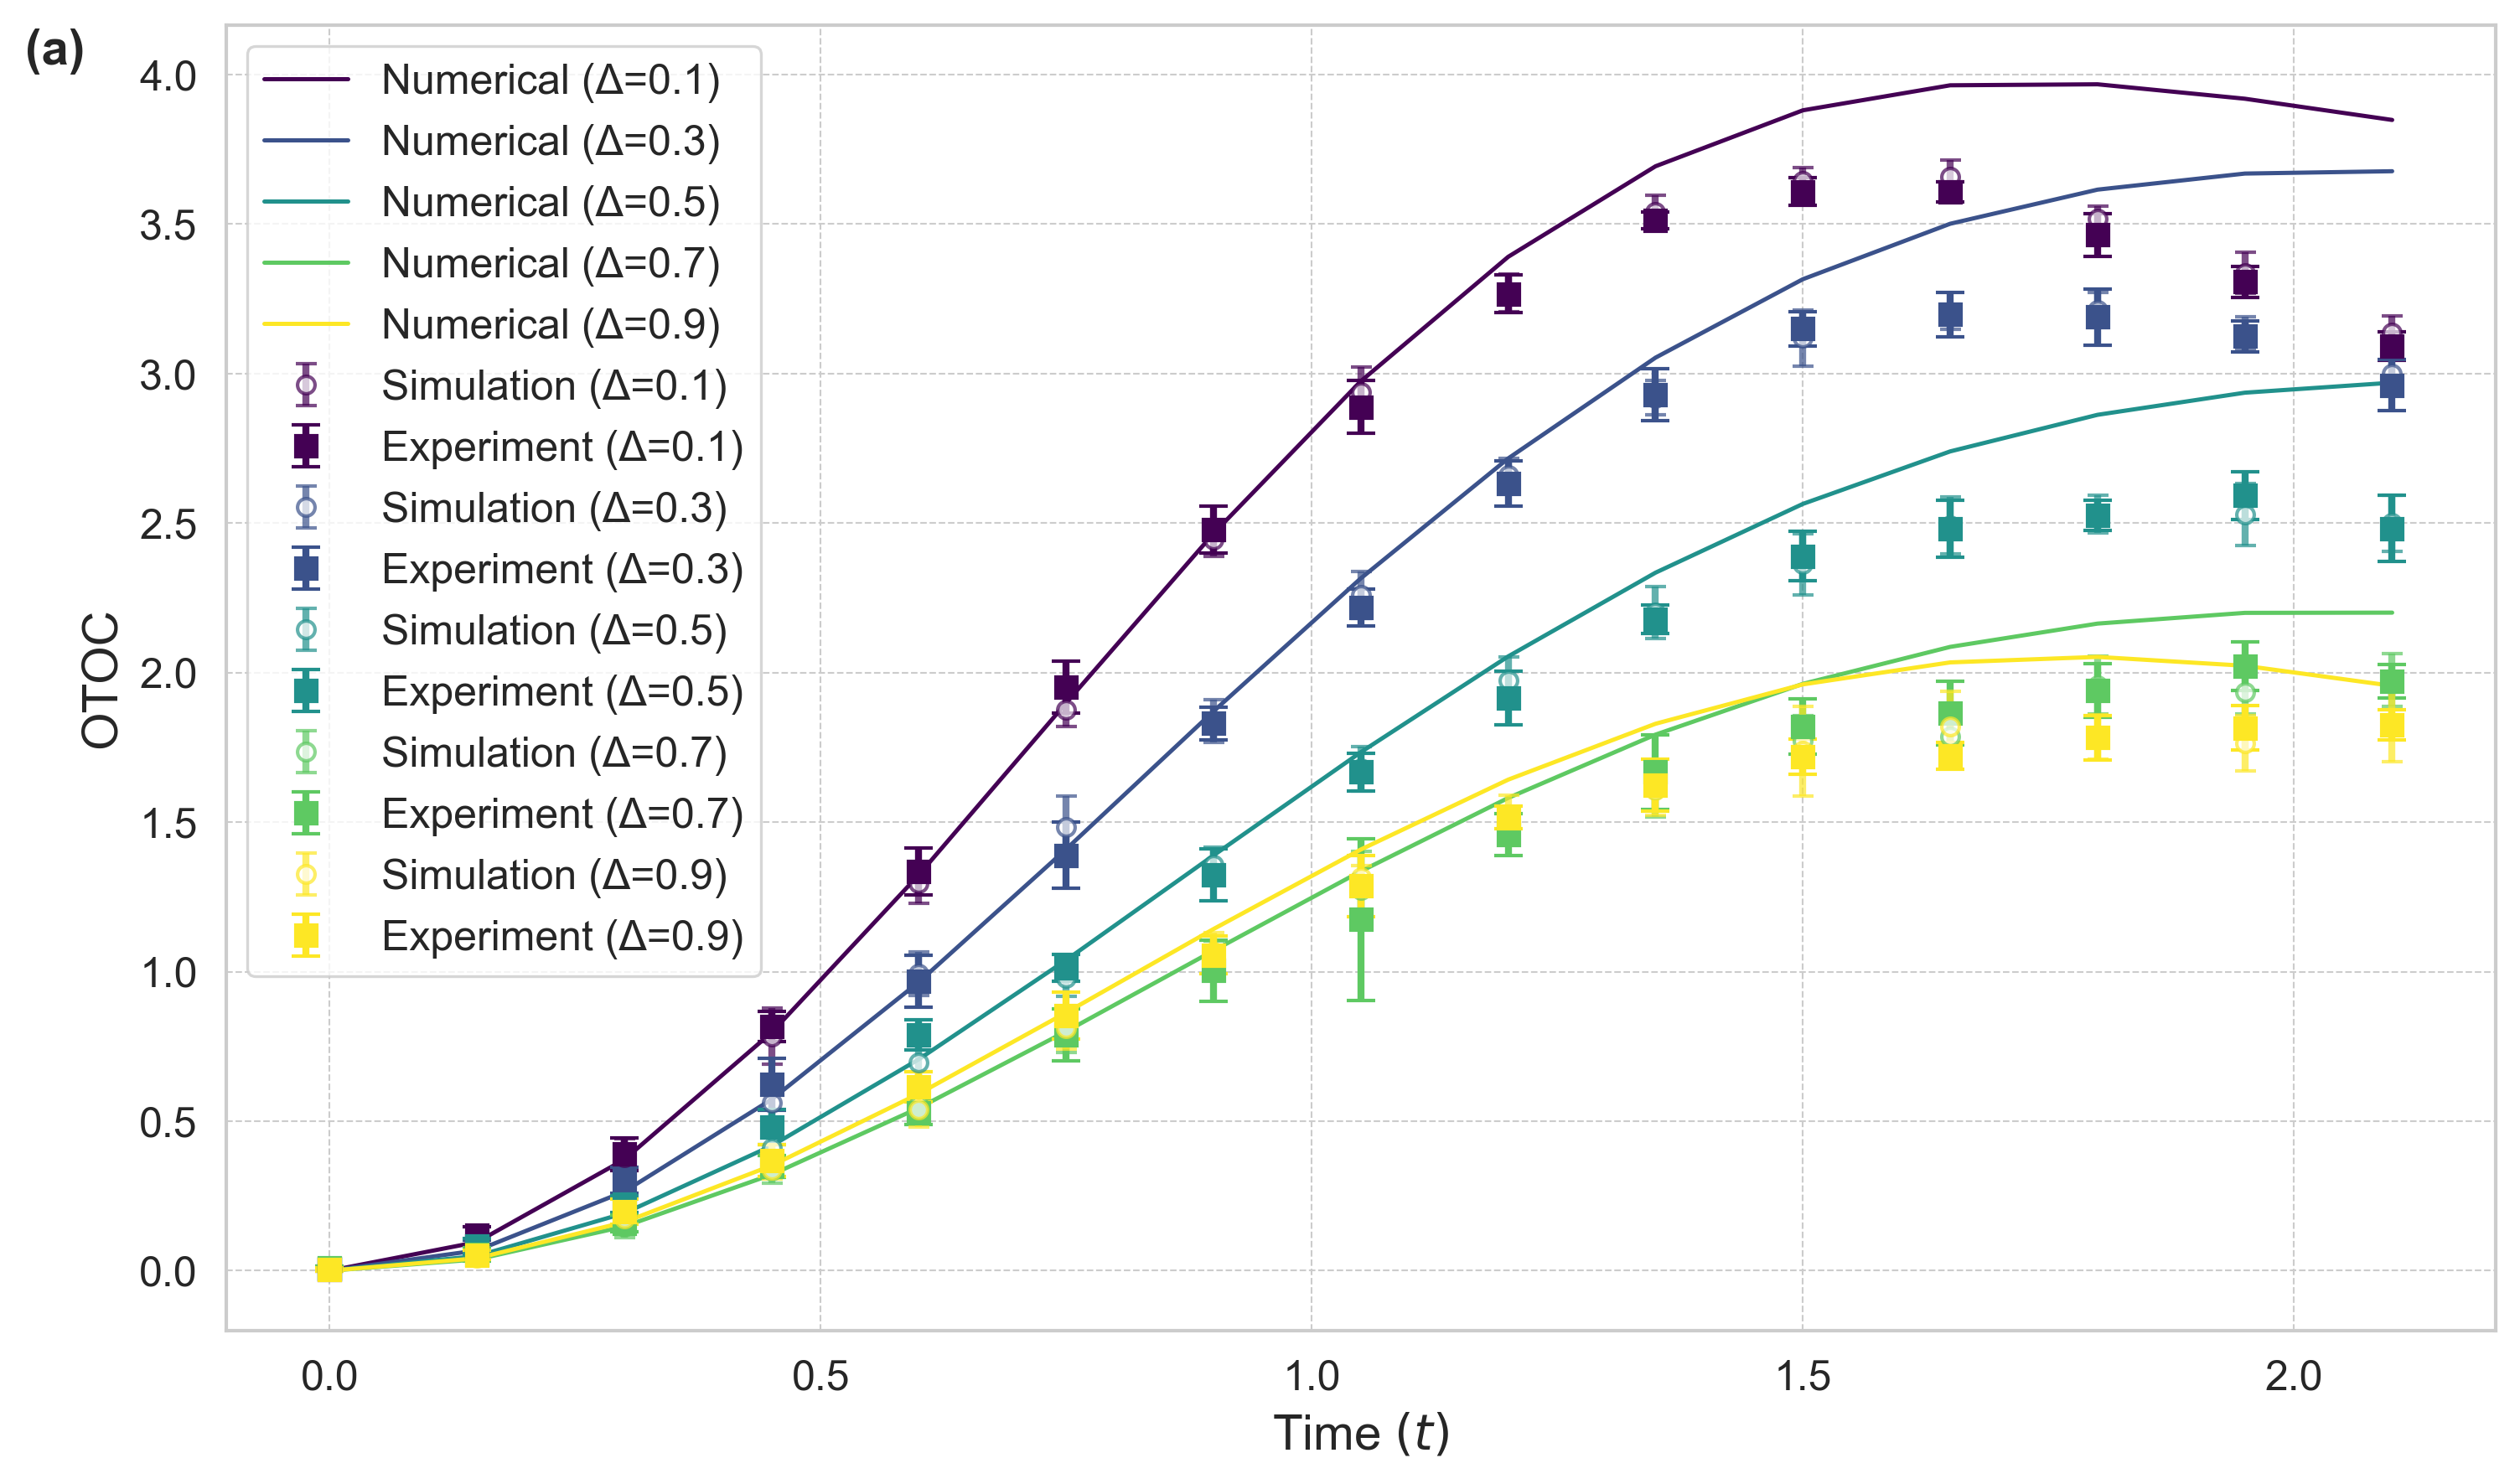

In [31]:
if __name__ == '__main__':

    # ==========================================================================
    # --- フェーズ 3: 結果のプロット ---
    # ==========================================================================
    print("\n--- Plotting All Available Results ---")
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, len(DELTA_LIST_OTOC)))
    
    for i, delta in enumerate(DELTA_LIST_OTOC):
        color = colors[i]
        
        if delta in all_results['numerical']:
            ax.plot(T_LIST, all_results['numerical'][delta], '-', color=color, label=f"Numerical (Δ={delta})")
            
        if delta in all_results['simulation']:
            sim_means, sim_stds = all_results['simulation'][delta]
            ax.errorbar(T_LIST, sim_means, yerr=sim_stds, fmt='o', mfc='white', color=color,
                        ecolor=color, alpha=0.7, elinewidth=2, capsize=3,
                        label=f"Simulation (Δ={delta})", markersize=5)
    
        if delta in all_results['experiment']:
            exp_means, exp_stds = all_results['experiment'][delta]
            ax.errorbar(T_LIST, exp_means, yerr=exp_stds, fmt='s', color=color,
                        ecolor=color, elinewidth=2, capsize=4,
                        label=f"Experiment (Δ={delta})", markersize=6)

    ax.set_xlabel('Time 'r'$(t)$', fontsize=14)
    ax.set_ylabel('OTOC', fontsize=14)
    ax.text(-0.31, 4.0, '(a)', fontsize=14, va='bottom', ha='left', weight='bold')
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=12)
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    
    plot_filename = f'OTOC_Comparison_RTM_EXP.pdf'
    fig.savefig(plot_filename)
    print(f"Plot saved to '{plot_filename}'")
    
    plt.show()